In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import torch
from scipy.signal import savgol_filter

Raw data shape: (310, 300)
Number of interacting pairs: 155
Using pair: (46, 47)
Training trajectory points: 160
Testing trajectory points: 40
Training samples: (320, 29)
Testing samples: (80, 29)
Number of training features: 29
Epoch 0, Loss 0.000003, MSE 0.000003
Epoch 500, Loss 0.000002, MSE 0.000002
Epoch 1000, Loss 0.000002, MSE 0.000002
Epoch 1500, Loss 0.000002, MSE 0.000002
Epoch 2000, Loss 0.000002, MSE 0.000002
Epoch 2500, Loss 0.000002, MSE 0.000002
Epoch 3000, Loss 0.000002, MSE 0.000002
Epoch 3500, Loss 0.000002, MSE 0.000002
Epoch 4000, Loss 0.000002, MSE 0.000002
Epoch 4500, Loss 0.000002, MSE 0.000002

Best epoch: 3642
Best loss: 1.5978861256371601e-06

Training MSE: 1.521247715308268e-06
Test MSE: 3.858200805280404e-06

Training RMSE: 0.0012333887121699582
Test RMSE: 0.0019642303340699136

Number of learned coefficients: 29

Discovered terms
----------------
0.001233 * 1
-0.001323 * v
0.010319 * v^2
0.004708 * Gaussian(0.00) dv
-0.002936 * Gaussian(1.00) dv


mean: 0.0

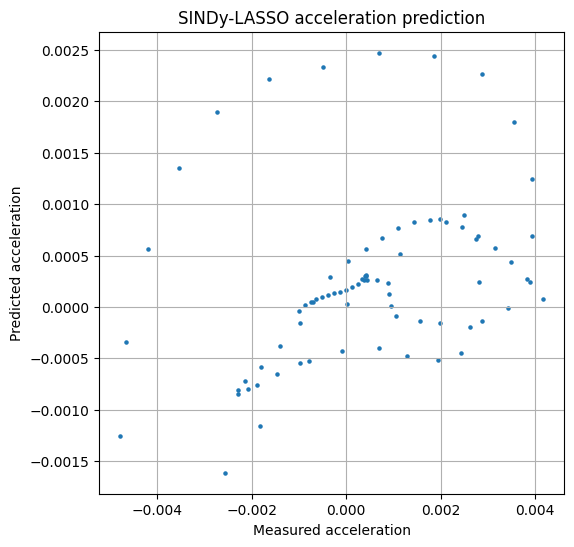

In [16]:
np.random.seed(42)


# load data

data = np.genfromtxt("pnas.2016602118.sd02.txt")
print("Raw data shape:", data.shape)


# parameters

dt = 10.0
num_cells = data.shape[0]

# small constant to prevent division by zero

epsilon = 0.05

# Gaussian basis parameters

centers = np.linspace(0, 1, 5)
sigma = 0.15


# shared interaction feature library

# this SAME function is used during both
# training and trajectory prediction
def build_phi_library(R_scaled):

    gaussians = [
        np.exp(
            -(R_scaled - c)**2 /
            (2 * sigma**2)
        )
        for c in centers
    ]

    phi_library = np.column_stack([
        np.ones_like(R_scaled),
        R_scaled,
        1.0 / (R_scaled + epsilon),
        1.0 / (R_scaled + epsilon)**2,
        np.exp(-R_scaled),
        np.exp(-2 * R_scaled),
        *gaussians
    ])

    return phi_library


# cells are already paired:

# (0,1)

# (2,3)

# (4,5)

# make pairs

pairs = []

for i in range(0, num_cells - 1, 2):
    pairs.append((i, i + 1))

print("Number of interacting pairs:", len(pairs))


# choose ONE interacting pair

pair_index = 23
i, j = pairs[pair_index]

print("Using pair:", (i, j))


# trajectory of cell i
xi = data[i]


# trajectory for cell j
xj = data[j]


# remove NaNs
xi = xi[~np.isnan(xi)]
xj = xj[~np.isnan(xj)]


# get shorter length, make both equal
length = min(len(xi), len(xj))

# need enough points for Savitzky-Golay filtering
if length < 21:
    raise ValueError("Not enough trajectory points for Savitzky-Golay filtering.")

# fix lengths to shorter one so both are same length
xi = xi[:length]
xj = xj[:length]


# smooth positions
xi_smooth = savgol_filter(
    xi,
    window_length=21,
    polyorder=3
)

xj_smooth = savgol_filter(
    xj,
    window_length=21,
    polyorder=3
)


# calculate velocity directly using Savitzky-Golay derivative
vi = savgol_filter(
    xi,
    window_length=21,
    polyorder=3,
    deriv=1,
    delta=dt
)

vj = savgol_filter(
    xj,
    window_length=21,
    polyorder=3,
    deriv=1,
    delta=dt
)


# calculate acceleration directly using Savitzky-Golay derivative
vdot_i = savgol_filter(
    xi,
    window_length=21,
    polyorder=3,
    deriv=2,
    delta=dt
)

vdot_j = savgol_filter(
    xj,
    window_length=21,
    polyorder=3,
    deriv=2,
    delta=dt
)


# use smoothed positions
xi = xi_smooth
xj = xj_smooth

# get distance
r = np.abs(xi - xj)


# split trajectory into first 80% and final 20%

split = int(0.8 * len(r))
print("Training trajectory points:", split)
print("Testing trajectory points:", len(r) - split)


# split positions, velocities, distances, and acceleration
xi_train = xi[:split]
xi_test = xi[split:]

xj_train = xj[:split]
xj_test = xj[split:]

vi_train = vi[:split]
vi_test = vi[split:]

vj_train = vj[:split]
vj_test = vj[split:]

vdot_i_train = vdot_i[:split]
vdot_i_test = vdot_i[split:]

vdot_j_train = vdot_j[:split]
vdot_j_test = vdot_j[split:]

r_train = r[:split]
r_test = r[split:]


# normalize distance for this pair
max_r = np.max(r_train)

if max_r == 0:
    raise ValueError("Maximum training distance is zero.")

R_train_scaled = r_train / max_r
R_test_scaled = r_test / max_r


# interaction library

# this is the SAME library used later
# during trajectory prediction
phi_library_train = build_phi_library(R_train_scaled)
phi_library_test = build_phi_library(R_test_scaled)


# SINDy library for F(x, v) cell i
F_i_train = np.column_stack([
    np.ones_like(xi_train),
    xi_train,
    xi_train**2,
    xi_train**3,
    vi_train,
    vi_train**2,
    xi_train * vi_train
])


F_i_test = np.column_stack([
    np.ones_like(xi_test),
    xi_test,
    xi_test**2,
    xi_test**3,
    vi_test,
    vi_test**2,
    xi_test * vi_test
])


# SINDy library for F(x, v) cell j
F_j_train = np.column_stack([
    np.ones_like(xj_train),
    xj_train,
    xj_train**2,
    xj_train**3,
    vj_train,
    vj_train**2,
    xj_train * vj_train
])


F_j_test = np.column_stack([
    np.ones_like(xj_test),
    xj_test,
    xj_test**2,
    xj_test**3,
    vj_test,
    vj_test**2,
    xj_test * vj_test
])


# multiplies every function by xj - xi
# this gives the direction to move
phi_x_i_train = (
    phi_library_train *
    (xj_train - xi_train)[:, None]
)

phi_x_i_test = (
    phi_library_test *
    (xj_test - xi_test)[:, None]
)


phi_v_i_train = (
    phi_library_train *
    (vj_train - vi_train)[:, None]
)

phi_v_i_test = (
    phi_library_test *
    (vj_test - vi_test)[:, None]
)


phi_x_j_train = (
    phi_library_train *
    (xi_train - xj_train)[:, None]
)

phi_x_j_test = (
    phi_library_test *
    (xi_test - xj_test)[:, None]
)


phi_v_j_train = (
    phi_library_train *
    (vi_train - vj_train)[:, None]
)

phi_v_j_test = (
    phi_library_test *
    (vi_test - vj_test)[:, None]
)


# full feature matrix
Theta_i_train = np.column_stack([
    F_i_train,
    phi_x_i_train,
    phi_v_i_train
])

Theta_i_test = np.column_stack([
    F_i_test,
    phi_x_i_test,
    phi_v_i_test
])


Theta_j_train = np.column_stack([
    F_j_train,
    phi_x_j_train,
    phi_v_j_train
])

Theta_j_test = np.column_stack([
    F_j_test,
    phi_x_j_test,
    phi_v_j_test
])


# theta has all of the features used to predict
# y = output (acceleration)
Theta_train = np.vstack([
    Theta_i_train,
    Theta_j_train
])

Theta_test = np.vstack([
    Theta_i_test,
    Theta_j_test
])


y_train = np.concatenate([
    vdot_i_train,
    vdot_j_train
])

y_test = np.concatenate([
    vdot_i_test,
    vdot_j_test
])


print("Training samples:", Theta_train.shape)
print("Testing samples:", Theta_test.shape)

# check feature count
print(
    "Number of training features:",
    Theta_train.shape[1]
)

if Theta_train.shape[1] != 29:

    raise ValueError(
        f"Expected 29 training features, "
        f"but found {Theta_train.shape[1]}."
    )

# standardize features
scaler = StandardScaler(
    with_mean=False
)

Theta_train_scaled = scaler.fit_transform(
    Theta_train
)

Theta_test_scaled = scaler.transform(
    Theta_test
)


# convert to PyTorch tensors
Theta_train_t = torch.tensor(
    Theta_train_scaled,
    dtype=torch.float32
)

Theta_test_t = torch.tensor(
    Theta_test_scaled,
    dtype=torch.float32
)

y_train_t = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_test_t = torch.tensor(
    y_test,
    dtype=torch.float32
)


# SINDy coefficients to learn
# one coefficient per library term
coeffs = torch.zeros(
    Theta_train.shape[1],
    requires_grad=True
)


# adam optimizer
optimizer = torch.optim.Adam(
    [coeffs],
    lr=0.0001
)


# LASSO parameters
# how strongly it punishes coefficients
lambda_l1 = 0.00001

epochs = 5000


# keep track of the best model

best_loss = float("inf")
best_coeffs = None
best_epoch = 0


# training loop
for epoch in range(epochs):
    # prediction:
    # theta*c = acceleration
    prediction = (
        Theta_train_t @ coeffs
    )

    # MSE loss
    mse_loss = torch.mean(
        (prediction - y_train_t)**2
    )

    # L1 penalty for sparsity
    l1_penalty = torch.sum(
        torch.abs(coeffs[1:])
    )


    # total LASSO loss
    loss = (
        mse_loss +
        lambda_l1 * l1_penalty
    )


    # save coefficients if this
    # is the best loss so far
    if loss.item() < best_loss:

        best_loss = loss.item()

        best_coeffs = (
            coeffs.detach().clone()
        )

        best_epoch = epoch


    # clear old gradients
    optimizer.zero_grad()


    # calculate gradients
    loss.backward()


    # update coefficients
    optimizer.step()


    # updates
    if epoch % 500 == 0:

        print(
            f"Epoch {epoch}, "
            f"Loss {loss.item():.6f}, "
            f"MSE {mse_loss.item():.6f}"
        )


# restore the best coefficients
with torch.no_grad():

    coeffs.copy_(
        best_coeffs
    )


print(
    "\nBest epoch:",
    best_epoch
)

print(
    "Best loss:",
    best_loss
)

# prediction on training data
with torch.no_grad():

    train_prediction = (
        Theta_train_t @ coeffs
    )

train_prediction = train_prediction.numpy()


# prediction on test data
with torch.no_grad():

    test_prediction = (
        Theta_test_t @ coeffs
    )

test_prediction = test_prediction.numpy()


# calculate MSE
train_mse = np.mean(
    (train_prediction - y_train)**2
)

test_mse = np.mean(
    (test_prediction - y_test)**2
)
train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

print("\nTraining MSE:", train_mse)
print("Test MSE:", test_mse)
print("\nTraining RMSE:", train_rmse)
print("Test RMSE:", test_rmse)

# recover learned coefficients
# detach from pytorch

learned_coeffs = coeffs.detach().numpy()


# coefficients in the original feature scale

coefficients = (
    learned_coeffs /
    scaler.scale_
)


# check coefficient count

print(
    "\nNumber of learned coefficients:",
    len(learned_coeffs)
)

if len(learned_coeffs) != 29:

    raise ValueError(
        "Number of learned coefficients is not 29."
    )


# print discovered equation

names = [
    # F(x,v)

    "1",
    "x",
    "x^2",
    "x^3",
    "v",
    "v^2",
    "x*v",

    # phi_x(r)*(xj-xi)

    "dx",
    "r dx",
    "1/(r+epsilon) dx",
    "1/(r+epsilon)^2 dx",
    "exp(-r) dx",
    "exp(-2r) dx",
    "Gaussian(0.00) dx",
    "Gaussian(0.25) dx",
    "Gaussian(0.50) dx",
    "Gaussian(0.75) dx",
    "Gaussian(1.00) dx",

    # phi_v(r)*(vj-vi)

    "dv",
    "r dv",
    "1/(r+epsilon) dv",
    "1/(r+epsilon)^2 dv",
    "exp(-r) dv",
    "exp(-2r) dv",
    "Gaussian(0.00) dv",
    "Gaussian(0.25) dv",
    "Gaussian(0.50) dv",
    "Gaussian(0.75) dv",
    "Gaussian(1.00) dv"
]


print("\nDiscovered terms")
print("----------------")

for name, c in zip(names, coefficients):

    if abs(c) > 1e-3:

        print(
            f"{c:.6f} * {name}"
        )


# print vdot data

all_vdot = np.concatenate([
    y_train,
    y_test
])


print("\n\nmean:", np.mean(all_vdot))
print("std:", np.std(all_vdot))
print("min:", np.min(all_vdot))
print("max:", np.max(all_vdot))



# prediction plot

plt.figure(figsize=(6, 6))

plt.scatter(
    y_test,
    test_prediction,
    s=5
)

plt.xlabel(
    "Measured acceleration"
)

plt.ylabel(
    "Predicted acceleration"
)

plt.title(
    "SINDy-LASSO acceleration prediction"
)

plt.grid()
plt.show()


Number of trajectory points: 200
Train/test split index: 160
Training fraction: 0.8

Initial state:
Cell i position: -8.32958043478261
Cell i velocity: -0.24818740217638924
Cell j position: -0.02536922077921055
Cell j velocity: -0.03297226181230431

Simulation successful: True
Solver message: The solver successfully reached the end of the integration interval.

Predicted points: 200

CONTINUOUS POSITION PREDICTION RMSE

TRAINING REGION
Cell i: 34.925599209178635
Cell j: 20.450129491025447
Overall: 28.61822213485569

TEST REGION
Cell i: 23.243872013513293
Cell j: 38.93007399030225
Overall: 32.06109984912397

Train/test boundary on plot: 80.0


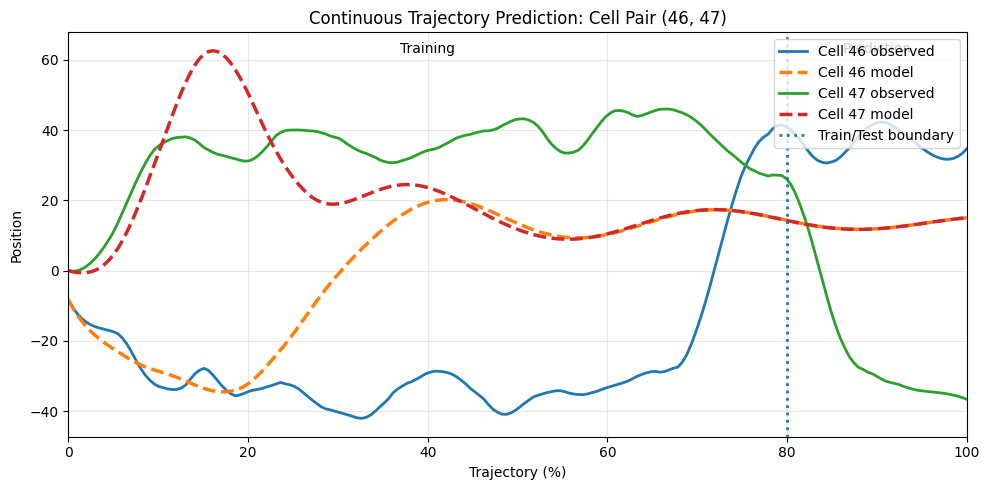

In [17]:

from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt


# Predict the full trajectory using the learned model
# Start at t = 0 and simulate through both the training
# and prediction regions without restarting at the 80% split.


# Build the feature vector for the current cell states

def make_theta_row(
    xi_now,
    vi_now,
    xj_now,
    vj_now
):

    # Calculate the distance between the cells

    r_now = abs(
        xi_now - xj_now
    )


    # Normalize using the maximum distance from training

    R_scaled = (
        r_now / max_r
    )


    # Use the same interaction library as during training

    phi = build_phi_library(
        np.array([
            R_scaled
        ])
    )[0]


    # Build the features for cell i

    # Use the same seven self-dynamics terms as during training

    F_i = np.array([
        1.0,
        xi_now,
        xi_now**2,
        xi_now**3,
        vi_now,
        vi_now**2,
        xi_now * vi_now
    ])


    # Position interaction features

    phi_x_i = (
        phi *
        (xj_now - xi_now)
    )


    # Velocity interaction features

    phi_v_i = (
        phi *
        (vj_now - vi_now)
    )


    # Combine the features for cell i

    theta_i = np.concatenate([
        F_i,
        phi_x_i,
        phi_v_i
    ])


    # Build the features for cell j

    F_j = np.array([
        1.0,
        xj_now,
        xj_now**2,
        xj_now**3,
        vj_now,
        vj_now**2,
        xj_now * vj_now
    ])


    # Reverse the position difference for cell j

    phi_x_j = (
        phi *
        (xi_now - xj_now)
    )


    # Reverse the velocity difference for cell j

    phi_v_j = (
        phi *
        (vi_now - vj_now)
    )


    # Combine the features for cell j

    theta_j = np.concatenate([
        F_j,
        phi_x_j,
        phi_v_j
    ])


    return theta_i, theta_j


# Define the learned differential equations

def learned_dynamics(
    t,
    state
):

    # Get the current predicted positions and velocities

    xi_now, vi_now, xj_now, vj_now = state


    # Build the features using the current predicted state

    theta_i, theta_j = make_theta_row(
        xi_now,
        vi_now,
        xj_now,
        vj_now
    )


    # Apply the same feature scaling used during training

    theta_i_scaled = scaler.transform(
        theta_i.reshape(1, -1)
    )[0]


    theta_j_scaled = scaler.transform(
        theta_j.reshape(1, -1)
    )[0]


    # Predict acceleration using the learned coefficients
    # a_hat = Theta c

    ai = (
        theta_i_scaled @
        learned_coeffs
    )


    aj = (
        theta_j_scaled @
        learned_coeffs
    )


    # Return the derivatives for both cells
    # dxi/dt = vi
    # dvi/dt = ai
    # dxj/dt = vj
    # dvj/dt = aj

    return [
        vi_now,
        ai,
        vj_now,
        aj
    ]


# Create the time axis for the full trajectory

num_points = len(xi)


# Keep time in minutes since velocities and accelerations
# were calculated using dt = 10 minutes.
# Convert to percentages later for the plot.

time_full = (
    np.arange(num_points) *
    dt
)


print(
    "Number of trajectory points:",
    num_points
)

print(
    "Train/test split index:",
    split
)

print(
    "Training fraction:",
    split / num_points
)


# Set the initial state using the first observed point
# The model is initialized only once at t = 0.

initial_state = [
    xi[0],
    vi[0],
    xj[0],
    vj[0]
]


print(
    "\nInitial state:"
)

print(
    "Cell i position:",
    xi[0]
)

print(
    "Cell i velocity:",
    vi[0]
)

print(
    "Cell j position:",
    xj[0]
)

print(
    "Cell j velocity:",
    vj[0]
)


# Run one continuous simulation across the full trajectory
# The model does not restart when it reaches the test region.

solution_full = solve_ivp(

    learned_dynamics,

    (
        time_full[0],
        time_full[-1]
    ),

    initial_state,

    t_eval=time_full,

    method="RK45",

    rtol=1e-6,

    atol=1e-8,

    max_step=dt / 5
)


# Check if the simulation ran successfully

print(
    "\nSimulation successful:",
    solution_full.success
)

print(
    "Solver message:",
    solution_full.message
)


if not solution_full.success:

    raise RuntimeError(
        "Continuous trajectory simulation failed: "
        +
        solution_full.message
    )


# Extract the predicted positions and velocities

xi_pred_full = (
    solution_full.y[0]
)

vi_pred_full = (
    solution_full.y[1]
)

xj_pred_full = (
    solution_full.y[2]
)

vj_pred_full = (
    solution_full.y[3]
)


print(
    "\nPredicted points:",
    len(xi_pred_full)
)


# Split the completed prediction into training and test portions
# This is only for calculating errors and does not restart the model.

xi_pred_train = (
    xi_pred_full[:split]
)

xi_pred_test = (
    xi_pred_full[split:]
)


xj_pred_train = (
    xj_pred_full[:split]
)

xj_pred_test = (
    xj_pred_full[split:]
)


# Calculate position RMSE for the training region

train_position_rmse_i = np.sqrt(
    np.mean(
        (
            xi_pred_train -
            xi_train
        )**2
    )
)


train_position_rmse_j = np.sqrt(
    np.mean(
        (
            xj_pred_train -
            xj_train
        )**2
    )
)


train_position_rmse_overall = np.sqrt(
    (
        np.mean(
            (
                xi_pred_train -
                xi_train
            )**2
        )
        +
        np.mean(
            (
                xj_pred_train -
                xj_train
            )**2
        )
    )
    / 2
)


# Calculate position RMSE for the test region
# These predictions come from the simulation started at t = 0,
# without using observed values to restart at the split.

test_position_rmse_i = np.sqrt(
    np.mean(
        (
            xi_pred_test -
            xi_test
        )**2
    )
)


test_position_rmse_j = np.sqrt(
    np.mean(
        (
            xj_pred_test -
            xj_test
        )**2
    )
)


test_position_rmse_overall = np.sqrt(
    (
        np.mean(
            (
                xi_pred_test -
                xi_test
            )**2
        )
        +
        np.mean(
            (
                xj_pred_test -
                xj_test
            )**2
        )
    )
    / 2
)


# Print the training and test position errors

print(
    "\n===================================="
)

print(
    "CONTINUOUS POSITION PREDICTION RMSE"
)

print(
    "===================================="
)


print(
    "\nTRAINING REGION"
)

print(
    "Cell i:",
    train_position_rmse_i
)

print(
    "Cell j:",
    train_position_rmse_j
)

print(
    "Overall:",
    train_position_rmse_overall
)


print(
    "\nTEST REGION"
)

print(
    "Cell i:",
    test_position_rmse_i
)

print(
    "Cell j:",
    test_position_rmse_j
)

print(
    "Overall:",
    test_position_rmse_overall
)


# Convert the time axis to percentages for plotting
# The actual ODE simulation was run in minutes.

time_percent = np.linspace(
    0,
    100,
    num_points
)


# Find where the training region ends on the plot

split_percent = (
    100 *
    split /
    num_points
)


print(
    "\nTrain/test boundary on plot:",
    split_percent
)


# Plot the observed and predicted cell trajectories

plt.figure(
    figsize=(10, 5)
)


# Plot the observed positions for cell i

plt.plot(
    time_percent,
    xi,
    linewidth=2,
    label=f"Cell {i} observed"
)


# Plot the predicted positions for cell i

plt.plot(
    time_percent,
    xi_pred_full,
    "--",
    linewidth=2.5,
    label=f"Cell {i} model"
)


# Plot the observed positions for cell j

plt.plot(
    time_percent,
    xj,
    linewidth=2,
    label=f"Cell {j} observed"
)


# Plot the predicted positions for cell j

plt.plot(
    time_percent,
    xj_pred_full,
    "--",
    linewidth=2.5,
    label=f"Cell {j} model"
)


# Mark the boundary between training and testing
# This is only a visual marker, not a simulation restart.

plt.axvline(
    x=split_percent,
    linestyle=":",
    linewidth=2,
    label="Train/Test boundary"
)


# Add labels for the training and prediction regions

y_min, y_max = plt.ylim()

label_y = (
    y_max -
    0.05 * (y_max - y_min)
)


plt.text(
    split_percent / 2,
    label_y,
    "Training",
    horizontalalignment="center"
)


plt.text(
    (
        split_percent +
        100
    ) / 2,
    label_y,
    "Prediction",
    horizontalalignment="center"
)


# Add axis labels and finish formatting the plot

plt.xlim(
    0,
    100
)


plt.xlabel(
    "Trajectory (%)"
)


plt.ylabel(
    "Position"
)


plt.title(
    f"Continuous Trajectory Prediction: "
    f"Cell Pair ({i}, {j})"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.tight_layout()


plt.show()


#BASIC SINDY LIBRARY

Raw data shape: (310, 300)
Number of interacting pairs: 155
Using pair: (46, 47)
Training trajectory points: 160
Testing trajectory points: 40
Training samples: (320, 9)
Testing samples: (80, 9)
Number of training features: 9
Epoch 0, Loss 0.000003, MSE 0.000003
Epoch 500, Loss 0.000002, MSE 0.000002
Epoch 1000, Loss 0.000002, MSE 0.000002
Epoch 1500, Loss 0.000002, MSE 0.000002
Epoch 2000, Loss 0.000002, MSE 0.000002
Epoch 2500, Loss 0.000002, MSE 0.000002
Epoch 3000, Loss 0.000002, MSE 0.000002
Epoch 3500, Loss 0.000002, MSE 0.000002
Epoch 4000, Loss 0.000002, MSE 0.000002
Epoch 4500, Loss 0.000002, MSE 0.000002

Best epoch: 459
Best loss: 2.11133669836272e-06

Training MSE: 1.9880367465583382e-06
Test MSE: 4.357352909400075e-06

Training RMSE: 0.0014099775695231248
Test RMSE: 0.0020874273423044155

Number of learned coefficients: 9

Discovered terms
----------------
0.001620 * v
0.005933 * dv
-0.018529 * r dv
0.013688 * r^2 dv


mean: 0.00012946665968283877
std: 0.001782692473259229

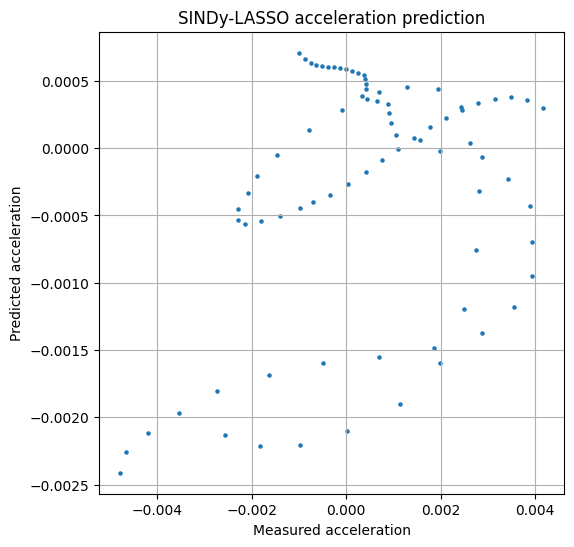

xi_pred shape: (40,)
xj_pred shape: (40,)

Cell i position RMSE: 37.50972237337592
Cell j position RMSE: 16.204273799054164
Overall position RMSE: 28.892540229983684


In [12]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from scipy.signal import savgol_filter
from scipy.integrate import solve_ivp

import torch


np.random.seed(42)


# Load the cell trajectory data

data = np.genfromtxt("pnas.2016602118.sd02.txt")
print("Raw data shape:", data.shape)


# Set the time step and number of cells

dt = 10.0
num_cells = data.shape[0]


# Build the interaction feature library
# Use the same function for training and trajectory prediction.

def build_phi_library(R_scaled):

    phi_library = np.column_stack([
        np.ones_like(R_scaled),
        R_scaled,
        R_scaled**2
    ])

    return phi_library


# The cells are paired in order: (0,1), (2,3), (4,5), etc.

pairs = []

for i in range(0, num_cells - 1, 2):
    pairs.append((i, i + 1))

print("Number of interacting pairs:", len(pairs))


# Choose a pair of interacting cells

pair_index = 23

i, j = pairs[pair_index]

print("Using pair:", (i, j))


# Get the position data for each cell

xi = data[i]

xj = data[j]


# Remove missing values

xi = xi[~np.isnan(xi)]
xj = xj[~np.isnan(xj)]


# Find the shorter trajectory length

length = min(len(xi), len(xj))


# Make sure there are enough points for smoothing

if length < 21:

    raise ValueError(
        "Not enough trajectory points for Savitzky-Golay filtering."
    )


# Make both trajectories the same length

xi = xi[:length]
xj = xj[:length]


# Smooth the position data to reduce noise

xi_smooth = savgol_filter(
    xi,
    window_length=21,
    polyorder=3
)

xj_smooth = savgol_filter(
    xj,
    window_length=21,
    polyorder=3
)


# Calculate velocity using the first derivative

vi = savgol_filter(
    xi,
    window_length=21,
    polyorder=3,
    deriv=1,
    delta=dt
)

vj = savgol_filter(
    xj,
    window_length=21,
    polyorder=3,
    deriv=1,
    delta=dt
)


# Calculate acceleration using the second derivative

vdot_i = savgol_filter(
    xi,
    window_length=21,
    polyorder=3,
    deriv=2,
    delta=dt
)

vdot_j = savgol_filter(
    xj,
    window_length=21,
    polyorder=3,
    deriv=2,
    delta=dt
)


# Use the smoothed positions from now on

xi = xi_smooth
xj = xj_smooth


# Calculate the distance between the cells

r = np.abs(xi - xj)


# Use the first 80% for training and the last 20% for testing

split = int(0.8 * len(r))

print("Training trajectory points:", split)
print("Testing trajectory points:", len(r) - split)


# Split positions, velocities, accelerations, and distances

xi_train = xi[:split]
xi_test = xi[split:]

xj_train = xj[:split]
xj_test = xj[split:]

vi_train = vi[:split]
vi_test = vi[split:]

vj_train = vj[:split]
vj_test = vj[split:]

vdot_i_train = vdot_i[:split]
vdot_i_test = vdot_i[split:]

vdot_j_train = vdot_j[:split]
vdot_j_test = vdot_j[split:]

r_train = r[:split]
r_test = r[split:]


# Normalize distance using the maximum training distance

max_r = np.max(r_train)

if max_r == 0:

    raise ValueError(
        "Maximum training distance is zero."
    )


R_train_scaled = r_train / max_r
R_test_scaled = r_test / max_r


# Build the interaction libraries for training and testing
# These same features are used later for trajectory prediction.

phi_library_train = build_phi_library(
    R_train_scaled
)

phi_library_test = build_phi_library(
    R_test_scaled
)


# Build the self-dynamics features for cell i

F_i_train = np.column_stack([
    np.ones_like(xi_train),
    xi_train,
    vi_train
])


F_i_test = np.column_stack([
    np.ones_like(xi_test),
    xi_test,
    vi_test
])


# Build the self-dynamics features for cell j

F_j_train = np.column_stack([
    np.ones_like(xj_train),
    xj_train,
    vj_train
])


F_j_test = np.column_stack([
    np.ones_like(xj_test),
    xj_test,
    vj_test
])


# Multiply the interaction functions by the position difference
# This accounts for the direction between the cells.

phi_x_i_train = (
    phi_library_train *
    (xj_train - xi_train)[:, None]
)

phi_x_i_test = (
    phi_library_test *
    (xj_test - xi_test)[:, None]
)


# Calculate velocity interaction features for cell i

phi_v_i_train = (
    phi_library_train *
    (vj_train - vi_train)[:, None]
)

phi_v_i_test = (
    phi_library_test *
    (vj_test - vi_test)[:, None]
)


# Calculate position interaction features for cell j
# The position difference is reversed.

phi_x_j_train = (
    phi_library_train *
    (xi_train - xj_train)[:, None]
)

phi_x_j_test = (
    phi_library_test *
    (xi_test - xj_test)[:, None]
)


# Calculate velocity interaction features for cell j

phi_v_j_train = (
    phi_library_train *
    (vi_train - vj_train)[:, None]
)

phi_v_j_test = (
    phi_library_test *
    (vi_test - vj_test)[:, None]
)


# Combine the features into a matrix for each cell

Theta_i_train = np.column_stack([
    F_i_train,
    phi_x_i_train,
    phi_v_i_train
])

Theta_i_test = np.column_stack([
    F_i_test,
    phi_x_i_test,
    phi_v_i_test
])


Theta_j_train = np.column_stack([
    F_j_train,
    phi_x_j_train,
    phi_v_j_train
])

Theta_j_test = np.column_stack([
    F_j_test,
    phi_x_j_test,
    phi_v_j_test
])


# Combine both cells' features into the training and test matrices
# The target values are the measured accelerations.

Theta_train = np.vstack([
    Theta_i_train,
    Theta_j_train
])

Theta_test = np.vstack([
    Theta_i_test,
    Theta_j_test
])


y_train = np.concatenate([
    vdot_i_train,
    vdot_j_train
])

y_test = np.concatenate([
    vdot_i_test,
    vdot_j_test
])


print("Training samples:", Theta_train.shape)
print("Testing samples:", Theta_test.shape)


# Check that the feature matrix contains nine features

print(
    "Number of training features:",
    Theta_train.shape[1]
)


if Theta_train.shape[1] != 9:

    raise ValueError(
        f"Expected 9 training features, "
        f"but found {Theta_train.shape[1]}."
    )


# Scale the features using the training data

scaler = StandardScaler(
    with_mean=False
)


Theta_train_scaled = scaler.fit_transform(
    Theta_train
)

Theta_test_scaled = scaler.transform(
    Theta_test
)


# Convert the data into PyTorch tensors

Theta_train_t = torch.tensor(
    Theta_train_scaled,
    dtype=torch.float32
)

Theta_test_t = torch.tensor(
    Theta_test_scaled,
    dtype=torch.float32
)

y_train_t = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_test_t = torch.tensor(
    y_test,
    dtype=torch.float32
)


# Initialize the coefficients that SINDy will learn
# Each feature has one coefficient.

coeffs = torch.zeros(
    Theta_train.shape[1],
    requires_grad=True
)


# Use Adam to optimize the coefficients

optimizer = torch.optim.Adam(
    [coeffs],
    lr=0.0001
)


# Set the L1 penalty and number of training epochs
# The L1 penalty encourages smaller or zero coefficients.

lambda_l1 = 0.00001

epochs = 5000


# Keep track of the model with the lowest loss

best_loss = float("inf")
best_coeffs = None
best_epoch = 0


# Train the model

for epoch in range(epochs):

    # Predict acceleration using the current coefficients

    prediction = (
        Theta_train_t @ coeffs
    )


    # Calculate mean squared error

    mse_loss = torch.mean(
        (prediction - y_train_t)**2
    )


    # Calculate the L1 penalty to encourage sparsity

    l1_penalty = torch.sum(
        torch.abs(coeffs[1:])
    )


    # Combine MSE and the L1 penalty

    loss = (
        mse_loss +
        lambda_l1 * l1_penalty
    )


    # Save the coefficients if the loss improves

    if loss.item() < best_loss:

        best_loss = loss.item()

        best_coeffs = (
            coeffs.detach().clone()
        )

        best_epoch = epoch


    # Clear gradients from the previous iteration

    optimizer.zero_grad()


    # Calculate the gradients

    loss.backward()


    # Update the coefficients

    optimizer.step()


    # Print training progress every 500 epochs

    if epoch % 500 == 0:

        print(
            f"Epoch {epoch}, "
            f"Loss {loss.item():.6f}, "
            f"MSE {mse_loss.item():.6f}"
        )


# Restore the coefficients with the lowest training loss

with torch.no_grad():

    coeffs.copy_(
        best_coeffs
    )


print(
    "\nBest epoch:",
    best_epoch
)


print(
    "Best loss:",
    best_loss
)


# Predict acceleration on the training data

with torch.no_grad():

    train_prediction = (
        Theta_train_t @ coeffs
    )


train_prediction = train_prediction.numpy()


# Predict acceleration on the test data

with torch.no_grad():

    test_prediction = (
        Theta_test_t @ coeffs
    )


test_prediction = test_prediction.numpy()


# Calculate training and test MSE

train_mse = np.mean(
    (train_prediction - y_train)**2
)

test_mse = np.mean(
    (test_prediction - y_test)**2
)


# Calculate training and test RMSE

train_rmse = np.sqrt(
    train_mse
)

test_rmse = np.sqrt(
    test_mse
)


print(
    "\nTraining MSE:",
    train_mse
)

print(
    "Test MSE:",
    test_mse
)

print(
    "\nTraining RMSE:",
    train_rmse
)

print(
    "Test RMSE:",
    test_rmse
)


# Get the learned coefficients from PyTorch

learned_coeffs = coeffs.detach().numpy()


# Convert coefficients back to the original feature scale

coefficients = (
    learned_coeffs /
    scaler.scale_
)


# Check that there are nine learned coefficients

print(
    "\nNumber of learned coefficients:",
    len(learned_coeffs)
)


if len(learned_coeffs) != 9:

    raise ValueError(
        "Number of learned coefficients is not 9."
    )


# Label the terms in the discovered equation

names = [

    # Self-dynamics terms
    "1",
    "x",
    "v",

    # Position interaction terms
    "dx",
    "r dx",
    "r^2 dx",

    # Velocity interaction terms
    "dv",
    "r dv",
    "r^2 dv"
]


print(
    "\nDiscovered terms"
)

print(
    "----------------"
)


# Print coefficients that are larger than the threshold

for name, c in zip(
    names,
    coefficients
):

    if abs(c) > 1e-3:

        print(
            f"{c:.6f} * {name}"
        )


# Combine acceleration values from training and testing

all_vdot = np.concatenate([
    y_train,
    y_test
])


# Print summary statistics for acceleration

print(
    "\n\nmean:",
    np.mean(all_vdot)
)

print(
    "std:",
    np.std(all_vdot)
)

print(
    "min:",
    np.min(all_vdot)
)

print(
    "max:",
    np.max(all_vdot)
)


# Plot measured acceleration against predicted acceleration

plt.figure(
    figsize=(6, 6)
)


plt.scatter(
    y_test,
    test_prediction,
    s=5
)


plt.xlabel(
    "Measured acceleration"
)

plt.ylabel(
    "Predicted acceleration"
)

plt.title(
    "SINDy-LASSO acceleration prediction"
)

plt.grid()

plt.show()


# Predict cell positions using the learned dynamics


# Find the number of points in the test region

num_test_points = len(xi_test)


# Create a time axis starting at zero for the test simulation

time_test = np.arange(
    num_test_points
) * dt


# Build the feature vectors for a given cell state

def make_theta_row(
    xi_now,
    vi_now,
    xj_now,
    vj_now
):

    # Calculate the current distance between the cells

    r_now = abs(
        xi_now - xj_now
    )


    # Normalize distance using the training maximum

    R_scaled = (
        r_now / max_r
    )


    # Build the same interaction features used during training

    phi = build_phi_library(
        np.array([
            R_scaled
        ])
    )[0]


    # Build the features for cell i

    F_i = np.array([
        1.0,
        xi_now,
        vi_now
    ])


    phi_x_i = (
        phi *
        (xj_now - xi_now)
    )


    phi_v_i = (
        phi *
        (vj_now - vi_now)
    )


    theta_i = np.concatenate([
        F_i,
        phi_x_i,
        phi_v_i
    ])


    # Build the features for cell j

    F_j = np.array([
        1.0,
        xj_now,
        vj_now
    ])


    phi_x_j = (
        phi *
        (xi_now - xj_now)
    )


    phi_v_j = (
        phi *
        (vi_now - vj_now)
    )


    theta_j = np.concatenate([
        F_j,
        phi_x_j,
        phi_v_j
    ])


    return theta_i, theta_j


# Define the ODE using the learned model

def learned_dynamics(
    t,
    state
):

    # Get the current positions and velocities

    xi_now, vi_now, xj_now, vj_now = state


    # Build the features at the current state

    theta_i, theta_j = make_theta_row(
        xi_now,
        vi_now,
        xj_now,
        vj_now
    )


    # Apply the same scaling used during training

    theta_i_scaled = scaler.transform(
        theta_i.reshape(1, -1)
    )[0]


    theta_j_scaled = scaler.transform(
        theta_j.reshape(1, -1)
    )[0]


    # Predict acceleration for each cell

    ai = (
        theta_i_scaled @
        learned_coeffs
    )

    aj = (
        theta_j_scaled @
        learned_coeffs
    )


    # Return the derivatives of position and velocity
    # dxi/dt = vi
    # dvi/dt = ai
    # dxj/dt = vj
    # dvj/dt = aj

    return [
        vi_now,
        ai,
        vj_now,
        aj
    ]


# Start the simulation at the beginning of the test region

initial_state = [
    xi[split],
    vi[split],
    xj[split],
    vj[split]
]


# Solve the ODE to predict cell trajectories

solution = solve_ivp(
    learned_dynamics,
    [
        time_test[0],
        time_test[-1]
    ],
    initial_state,
    t_eval=time_test,
    method="RK45",
    rtol=1e-6,
    atol=1e-8,
    max_step=dt / 5
)


# Extract the predicted positions for both cells

xi_pred = solution.y[0]
xj_pred = solution.y[2]


print(
    "xi_pred shape:",
    xi_pred.shape
)

print(
    "xj_pred shape:",
    xj_pred.shape
)


# Calculate position RMSE for each cell

position_rmse_i = np.sqrt(
    np.mean(
        (xi_pred - xi_test)**2
    )
)


position_rmse_j = np.sqrt(
    np.mean(
        (xj_pred - xj_test)**2
    )
)


# Calculate the overall position RMSE

position_rmse_overall = np.sqrt(
    (
        np.mean(
            (xi_pred - xi_test)**2
        )
        +
        np.mean(
            (xj_pred - xj_test)**2
        )
    ) / 2
)


# Print the position prediction errors

print(
    "\nCell i position RMSE:",
    position_rmse_i
)

print(
    "Cell j position RMSE:",
    position_rmse_j
)

print(
    "Overall position RMSE:",
    position_rmse_overall
)


Saved baseline model.
Baseline scaler expects: 9 features
Baseline coefficients: 9
Baseline scaler feature count: 9
Baseline coefficient count: 9
Trajectory theta feature count: 9

Total trajectory points: 200
Training points: 160
Prediction points: 40

Baseline initial state:
[np.float64(-8.32958043478261), np.float64(-0.24818740217638924), np.float64(-0.02536922077921055), np.float64(-0.03297226181230431)]

Baseline simulation successful: True
Solver message: The solver successfully reached the end of the integration interval.
Predicted trajectory points: 200

BASELINE CONTINUOUS TRAJECTORY RMSE

TRAINING:
Cell 46: 53.62678090119664
Cell 47: 52.2560814995061
Overall: 52.9458670885083

PREDICTION:
Cell 46: 50.72812418233061
Cell 47: 88.89746281219709
Overall: 72.37437902152917


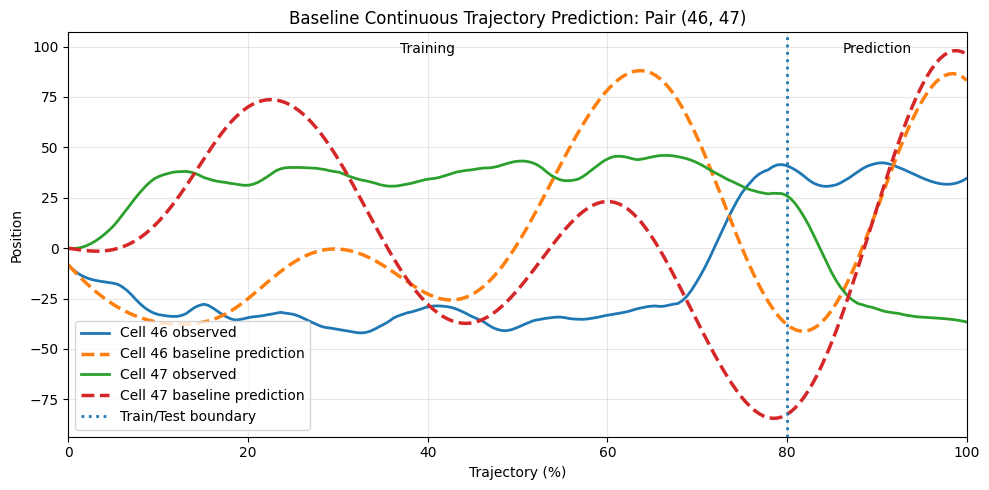

In [11]:

# Save the baseline model settings for later use

baseline_scaler = scaler
baseline_learned_coeffs = learned_coeffs.copy()
baseline_max_r = max_r

print("Saved baseline model.")
print(
    "Baseline scaler expects:",
    baseline_scaler.n_features_in_,
    "features"
)

print(
    "Baseline coefficients:",
    len(baseline_learned_coeffs)
)

from scipy.integrate import solve_ivp
import numpy as np
import matplotlib.pyplot as plt


# Simulate trajectories using the baseline model
# The baseline model uses nine candidate features:
# Three features for each cell's own motion:
# 1, x, v
# Three position interaction features:
# dx, r*dx, r^2*dx
# Three velocity interaction features:
# dv, r*dv, r^2*dv
# Start the simulation at t = 0.
# Keep the simulation running through the train/test split.


# Build the baseline interaction library
# Use the same three functions as in training.

def build_phi_library_baseline(
    R_scaled
):

    phi_library = np.column_stack([

        # 1
        np.ones_like(
            R_scaled
        ),

        # r
        R_scaled,

        # r^2
        R_scaled**2
    ])

    return phi_library


# Build the nine features for each cell

def make_theta_row_baseline(
    xi_now,
    vi_now,
    xj_now,
    vj_now
):

    # Find the distance between the two cells.

    r_now = abs(
        xi_now -
        xj_now
    )


    # Scale distance using the maximum from training.

    R_scaled = (
        r_now /
        baseline_max_r
    )


    # Calculate the baseline interaction terms.
    # [1, r, r^2]

    phi = build_phi_library_baseline(
        np.array([
            R_scaled
        ])
    )[0]


    # Check the number of interaction terms.

    if len(phi) != 3:

        raise ValueError(
            f"Baseline phi library has "
            f"{len(phi)} terms instead of 3."
        )


    # Features for cell i

    # Use the three self-dynamics features.
    # The baseline only uses 1, x, and v,
    # not the seven-term full-model library.

    F_i = np.array([
        1.0,
        xi_now,
        vi_now
    ])


    # Position interaction features:
    # [1, r, r²] * Δx

    phi_x_i = (
        phi *
        (
            xj_now -
            xi_now
        )
    )


    # Velocity interaction features:
    # [1, r, r²] * Δv

    phi_v_i = (
        phi *
        (
            vj_now -
            vi_now
        )
    )


    # Combine the nine features.

    theta_i = np.concatenate([
        F_i,
        phi_x_i,
        phi_v_i
    ])


    # Features for cell j

    F_j = np.array([
        1.0,
        xj_now,
        vj_now
    ])


    # Reverse the position difference for cell j.

    phi_x_j = (
        phi *
        (
            xi_now -
            xj_now
        )
    )


    # Reverse the velocity difference for cell j.

    phi_v_j = (
        phi *
        (
            vi_now -
            vj_now
        )
    )


    theta_j = np.concatenate([
        F_j,
        phi_x_j,
        phi_v_j
    ])


    # Check that each cell has nine features.

    if len(theta_i) != 9:

        raise ValueError(
            f"Cell i baseline theta has "
            f"{len(theta_i)} features. "
            "Expected 9."
        )


    if len(theta_j) != 9:

        raise ValueError(
            f"Cell j baseline theta has "
            f"{len(theta_j)} features. "
            "Expected 9."
        )


    return theta_i, theta_j


# Check model dimensions before solving the ODE

print(
    "Baseline scaler feature count:",
    baseline_scaler.n_features_in_
)

print(
    "Baseline coefficient count:",
    len(baseline_learned_coeffs)
)


test_theta_i, test_theta_j = (
    make_theta_row_baseline(
        xi[0],
        vi[0],
        xj[0],
        vj[0]
    )
)


print(
    "Trajectory theta feature count:",
    len(test_theta_i)
)


if baseline_scaler.n_features_in_ != 9:

    raise ValueError(
        "baseline_scaler is not the "
        "9-term baseline scaler."
    )


if len(
    baseline_learned_coeffs
) != 9:

    raise ValueError(
        "baseline_learned_coeffs does not "
        "contain 9 coefficients."
    )


# Define the learned baseline dynamics

def learned_dynamics_baseline(
    t,
    state
):

    # Get the current predicted positions and velocities.

    xi_now, vi_now, xj_now, vj_now = (
        state
    )


    # Build the nine features at the current state.

    theta_i, theta_j = (
        make_theta_row_baseline(
            xi_now,
            vi_now,
            xj_now,
            vj_now
        )
    )


    # Use the scaler fitted during baseline training.

    theta_i_scaled = (
        baseline_scaler.transform(
            theta_i.reshape(
                1,
                -1
            )
        )[0]
    )


    theta_j_scaled = (
        baseline_scaler.transform(
            theta_j.reshape(
                1,
                -1
            )
        )[0]
    )


    # Predict acceleration from the learned coefficients.
    # a_hat = Theta c

    ai = (
        theta_i_scaled @
        baseline_learned_coeffs
    )


    aj = (
        theta_j_scaled @
        baseline_learned_coeffs
    )


    # Return the position and velocity derivatives.
    # dx_i/dt = v_i
    # dv_i/dt = a_i
    # dx_j/dt = v_j
    # dv_j/dt = a_j

    return [
        vi_now,
        ai,
        vj_now,
        aj
    ]


# Create the full time axis
# Use minutes, since each time step is 10 minutes.

num_points = len(
    xi
)


time_full = (
    np.arange(
        num_points
    )
    *
    dt
)


print(
    "\nTotal trajectory points:",
    num_points
)

print(
    "Training points:",
    split
)

print(
    "Prediction points:",
    num_points -
    split
)


# Set the initial state at t = 0

initial_state_baseline = [

    xi[0],

    vi[0],

    xj[0],

    vj[0]
]


print(
    "\nBaseline initial state:"
)

print(
    initial_state_baseline
)


# Run one continuous simulation
# Simulate from the beginning to the end of the trajectory.
# The initial conditions are set only at the start.
# The solver does not restart at the 80% split.

solution_baseline = solve_ivp(

    learned_dynamics_baseline,

    (
        time_full[0],
        time_full[-1]
    ),

    initial_state_baseline,

    t_eval=time_full,

    method="RK45",

    rtol=1e-6,

    atol=1e-8,

    max_step=dt / 5
)


# Check whether the solver finished successfully

print(
    "\nBaseline simulation successful:",
    solution_baseline.success
)

print(
    "Solver message:",
    solution_baseline.message
)


if not solution_baseline.success:

    raise RuntimeError(
        solution_baseline.message
    )


# Extract the predicted positions and velocities

xi_pred_baseline_full = (
    solution_baseline.y[0]
)

vi_pred_baseline_full = (
    solution_baseline.y[1]
)

xj_pred_baseline_full = (
    solution_baseline.y[2]
)

vj_pred_baseline_full = (
    solution_baseline.y[3]
)


print(
    "Predicted trajectory points:",
    len(
        xi_pred_baseline_full
    )
)


# Split the simulated trajectory into training and test portions
# Use the split only to calculate errors.
# The ODE simulation is not restarted.

xi_pred_baseline_train = (
    xi_pred_baseline_full[
        :split
    ]
)


xi_pred_baseline_test = (
    xi_pred_baseline_full[
        split:
    ]
)


xj_pred_baseline_train = (
    xj_pred_baseline_full[
        :split
    ]
)


xj_pred_baseline_test = (
    xj_pred_baseline_full[
        split:
    ]
)


# Calculate position RMSE on the training portion

baseline_train_position_rmse_i = (
    np.sqrt(
        np.mean(
            (
                xi_pred_baseline_train -
                xi_train
            )**2
        )
    )
)


baseline_train_position_rmse_j = (
    np.sqrt(
        np.mean(
            (
                xj_pred_baseline_train -
                xj_train
            )**2
        )
    )
)


baseline_train_position_rmse_overall = (
    np.sqrt(
        (
            np.mean(
                (
                    xi_pred_baseline_train -
                    xi_train
                )**2
            )
            +
            np.mean(
                (
                    xj_pred_baseline_train -
                    xj_train
                )**2
            )
        )
        / 2
    )
)


# Calculate position RMSE on the test portion
# The test predictions continue from the original initial state.

baseline_test_position_rmse_i = (
    np.sqrt(
        np.mean(
            (
                xi_pred_baseline_test -
                xi_test
            )**2
        )
    )
)


baseline_test_position_rmse_j = (
    np.sqrt(
        np.mean(
            (
                xj_pred_baseline_test -
                xj_test
            )**2
        )
    )
)


baseline_test_position_rmse_overall = (
    np.sqrt(
        (
            np.mean(
                (
                    xi_pred_baseline_test -
                    xi_test
                )**2
            )
            +
            np.mean(
                (
                    xj_pred_baseline_test -
                    xj_test
                )**2
            )
        )
        / 2
    )
)


# Print training and prediction errors.
print(
    "\n===================================="
)

print(
    "BASELINE CONTINUOUS TRAJECTORY RMSE"
)

print(
    "===================================="
)


print(
    "\nTRAINING:"
)


print(
    f"Cell {i}:",
    baseline_train_position_rmse_i
)


print(
    f"Cell {j}:",
    baseline_train_position_rmse_j
)


print(
    "Overall:",
    baseline_train_position_rmse_overall
)


print(
    "\nPREDICTION:"
)


print(
    f"Cell {i}:",
    baseline_test_position_rmse_i
)


print(
    f"Cell {j}:",
    baseline_test_position_rmse_j
)


print(
    "Overall:",
    baseline_test_position_rmse_overall
)


# Show time as a percentage from 0 to 100.
time_percent = np.linspace(
    0,
    100,
    num_points
)


split_percent = (
    100 *
    split /
    num_points
)


# Plot observed and predicted trajectories.
plt.figure(
    figsize=(10, 5)
)


# Observed positions for cell i
plt.plot(
    time_percent,
    xi,
    linewidth=2,
    label=f"Cell {i} observed"
)


# Predicted positions for cell i
plt.plot(
    time_percent,
    xi_pred_baseline_full,
    "--",
    linewidth=2.5,
    label=f"Cell {i} baseline prediction"
)


# Observed positions for cell j
plt.plot(
    time_percent,
    xj,
    linewidth=2,
    label=f"Cell {j} observed"
)


# Predicted positions for cell j
plt.plot(
    time_percent,
    xj_pred_baseline_full,
    "--",
    linewidth=2.5,
    label=f"Cell {j} baseline prediction"
)


# Mark the train/test boundary.
plt.axvline(
    split_percent,
    linestyle=":",
    linewidth=2,
    label="Train/Test boundary"
)


# Label the training and prediction regions.
y_min, y_max = plt.ylim()


label_y = (
    y_max -
    0.05 *
    (
        y_max -
        y_min
    )
)


plt.text(
    split_percent / 2,
    label_y,
    "Training",
    horizontalalignment="center"
)


plt.text(
    (
        split_percent +
        100
    ) / 2,
    label_y,
    "Prediction",
    horizontalalignment="center"
)


# Add plot labels and formatting.
plt.xlim(
    0,
    100
)


plt.xlabel(
    "Trajectory (%)"
)


plt.ylabel(
    "Position"
)


plt.title(
    f"Baseline Continuous Trajectory Prediction: "
    f"Pair ({i}, {j})"
)


plt.legend()


plt.grid(
    alpha=0.3
)


plt.tight_layout()


plt.show()
